# Handling Null values and standarization
Second part

In [220]:
import pandas as pd

datos = pd.read_csv('../data/bronze/staging/stg1_casas_gam_full2.csv')
datos = datos[(datos['FlagsFeatures'] != 'remateHipotecario') & (datos['IsAuction'] == False)]
datos.info()

<class 'pandas.DataFrame'>
Index: 546 entries, 2 to 1263
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Total_area_m2     546 non-null    int64  
 1   Built_area_m2     546 non-null    int64  
 2   Rooms             546 non-null    int64  
 3   Bathrooms         546 non-null    int64  
 4   HalfBathrooms     546 non-null    int64  
 5   Parkings          546 non-null    int64  
 6   Antiguedad        504 non-null    float64
 7   Colonia           546 non-null    str    
 8   Price             546 non-null    int64  
 9   Maintenance_cost  546 non-null    int64  
 10  Address           543 non-null    str    
 11  PropertyType      546 non-null    str    
 12  IsAuction         546 non-null    bool   
 13  FlagsFeatures     56 non-null     str    
 14  HaveVideo         546 non-null    bool   
 15  Latitude          546 non-null    float64
 16  Longitude         546 non-null    float64
dtypes: bool(2), 

### Elimination of unuseful variables

In [221]:
datos.drop(columns=['FlagsFeatures','IsAuction', 'Address'], inplace=True)

### Elimination of Outliners

#### Total_area_m2

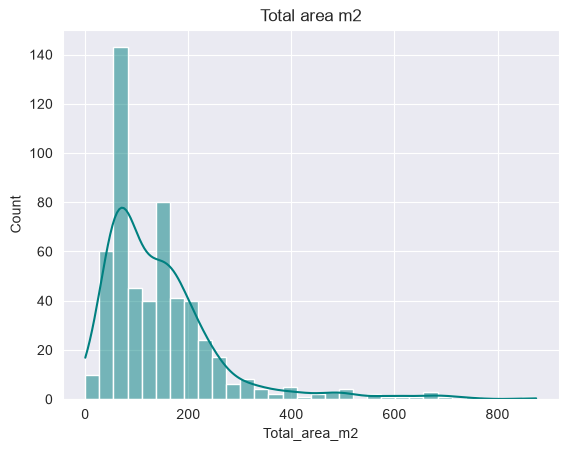

In [222]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('darkgrid')
sns.histplot(data=datos,x='Total_area_m2', color='teal', kde=True)
plt.title('Total area m2')
plt.show()

In [223]:
datos['Total_area_m2'].describe()

count    546.000000
mean     146.349817
std      117.240818
min        0.000000
25%       65.000000
50%      124.000000
75%      180.000000
max      875.000000
Name: Total_area_m2, dtype: float64

Based on the data, Its very clear that there are some outliners which have a extremely elevated **Total_area_m2**. In order to change them, we're going to visualize how many of them have gotten high values and eliminate them if necesary.

In [224]:
datos['cuartiles_total_area_m2'] = pd.qcut(datos['Total_area_m2'], q=8, labels=['q1','q2','q3','q4','q5','q6','q7','q8'])
print(datos['cuartiles_total_area_m2'].value_counts().sort_index())
q8 = datos[(datos['cuartiles_total_area_m2'] == 'q8')]
q8['Total_area_m2'].describe()

cuartiles_total_area_m2
q1    70
q2    77
q3    58
q4    70
q5    67
q6    70
q7    68
q8    66
Name: count, dtype: int64


count     66.000000
mean     388.090909
std      150.762751
min      242.000000
25%      266.250000
50%      327.000000
75%      485.000000
max      875.000000
Name: Total_area_m2, dtype: float64

In [225]:
# 1. Calcular el valor del percentil 99
limite_superior = datos['Total_area_m2'].quantile(0.98)

num = len(datos)
# 2. Filtrar el DataFrame para conservar solo lo que está por debajo o igual a ese límite
datos = datos[datos['Total_area_m2'] <= limite_superior]

# (Opcional) Verificar cuántas filas se eliminaron
print(f"Filas originales: {num}")
print(f"Filas actuales: {len(datos)}")



Filas originales: 546
Filas actuales: 535


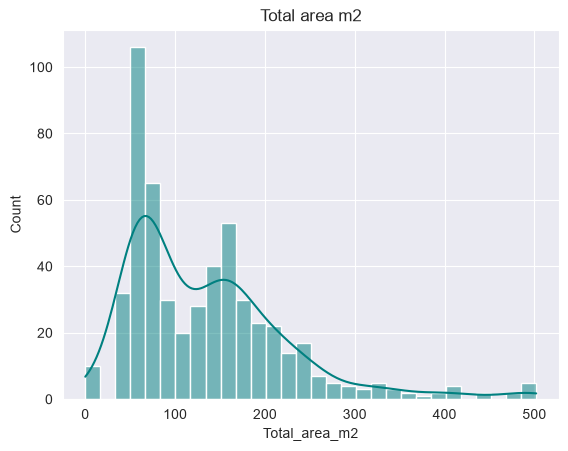

In [226]:
sns.histplot(data=datos,x='Total_area_m2', color='teal', kde=True, bins=30)
plt.title('Total area m2')
plt.show()

As we can see, the graphic has still outliners now on the left side, there shouldn't be registers with 0 m2 because that's physically impossible, its probable that there must have bn an error, With the intention to fix it, we'll see if the houses with 0 m2 on **Total_area_m2** have any value on **Built_area_m2**, if they've goteen a value, we'll assign it to **Total_area_m2**

In [227]:
datos[datos['Total_area_m2'] < 10][['Total_area_m2','Built_area_m2']].head(100)

,Total_area_m2,Built_area_m2
121,1,54
433,0,0
846,0,58
984,1,65
988,0,64
1171,0,50
1174,0,58
1199,0,75
1223,0,300
1248,0,117


In [ ]:
datos.loc[datos['Total_area_m2'] < 10, 'Total_area_m2'] = datos['Built_area_m2']
print(datos[datos['Total_area_m2'] < 10][['Total_area_m2', 'Built_area_m2']].head())

# We delete the values where both areas are 0
datos = datos[~((datos['Total_area_m2'] == 0) & (datos['Built_area_m2'] == 0))]


print(f"Total registers on the DataFrame After the dropping: {len(datos)}")


     Total_area_m2  Built_area_m2
433              0              0
Filas restantes en el DataFrame: 534


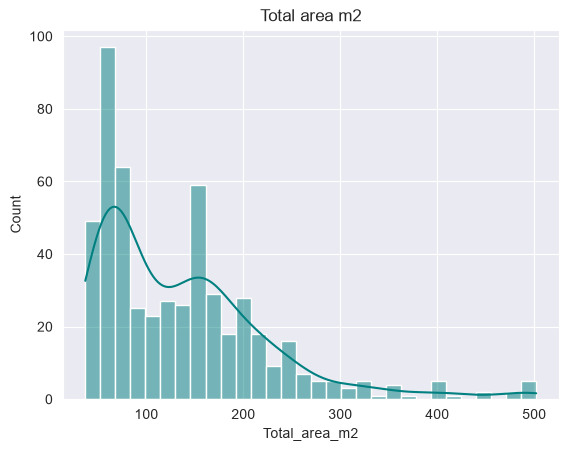

In [229]:
sns.histplot(data=datos,x='Total_area_m2', color='teal', kde=True, bins=30)
plt.title('Total area m2')
plt.show()

<hr />

In order to impute the value correctly, Let's start from the fact that most of the **Colonias** were made in a similar epoc, so, we'll divide the data using the **Colonias** and in the case that the variance of the **Antiguedad** isn't big, we'll impute using the media, otherwise, we'll use the median